**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**11 | Matched Random Forest vs Temporal CNN**

![Matched CNN and random forest workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/11_workflow.svg)

**Objective:** Compare Random Forest and a temporal 1D-CNN on identical HARTH source windows, participant partitions and Validation labels.

**Dataset:** The bounded HARTH v2.0 Development cohort from Notebook 10: 29 participants and 14,201 label-pure windows, with S023 and S032 excluded.

**Notebook Scope:** Extract 30 deterministic features for Random Forest and retain the six-channel time series for the CNN. Compare Validation metrics and participant-level errors on the same 2,701 windows. This is a matched-data Development comparison, not an architecture-only causal test or independent final Test evaluation.

**00. Colab Repository Setup**

In [51]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Research Environment**

In [52]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ---------- 4.  Machine Learning, Deep Learning Models and Metrics -----------
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, ConfusionMatrixDisplay, confusion_matrix
import torch

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, prepare_harth_window_cohort
from core.data_splitting import split_group_indices
from core.feature_engineering import extract_signal_features
from core.temporal_cnn import train_temporal_cnn
from core.ml_baselines import evaluate_predictions_by_subject, classification_class_report
from core.group_cross_validation import compare_models_by_subject

# ------------------- 6. Training Device and Setup Summary --------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Repository root:", root)
print("Research output directory:", output_dir)

Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Repository root: /content/human-movement-intelligence
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Recreate the Same Source-Window Cohort**

Use the 29 Development participants, eight documented activity classes and 500-window-per-person cap from Notebook 10. Both model representations are derived from the same 14,201 eligible windows; reserved Test sources are not loaded.

In [53]:
# ================= 02. Recreate Identical Raw-Window Cohort ==================

# ------------------- 1. Cohort and Sampling Configuration --------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
WINDOW_CAP = 500
assert len(DEVELOPMENT_SUBJECTS) == 29

# ---------------------- 2. Prepare Matched Raw Windows -----------------------
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    max_windows_per_subject=WINDOW_CAP,
    window_size=100, step_size=50, sampling_rate=50,
)
assert X.shape[0] == len(y) == len(metadata)
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ------------------------ 3. Inspect Source Alignment ------------------------
print("Shared raw windows:", X.shape)

display(overview[["subject_id", "eligible_windows", "sampled_windows", "observed_sampled_classes"]])


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared raw windows: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows,observed_sampled_classes
0,S006,6708,500,7
1,S008,7392,500,5
2,S009,201,201,4
3,S010,6077,500,6
4,S012,7309,500,8
5,S013,6402,500,8
6,S014,6299,500,8
7,S015,7453,500,8
8,S016,6272,500,7
9,S017,6678,500,8


**03. Preserve the Subject-Disjoint Partitions**

Reproduce the Notebook 10 participant split. Both models use the same Train and Validation windows; three other Development participants remain unused.

In [54]:
# ================ 03. Freeze the Subject-Disjoint Data Split =================

# ------------------- 1. Create Participant-Disjoint Split --------------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)
train_idx = parts["train"]
val_idx = parts["validation"]

# ------------------- 2. Verify Group and Signal Alignment --------------------
group_members = {
    name: set(metadata.iloc[rows]["subject_id"])
    for name, rows in parts.items()
}

assert not (group_members["train"] & group_members["validation"])
assert not (group_members["train"] & group_members["test"])
assert not (group_members["validation"] & group_members["test"])
X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

# --------------------- 3. Inspect Validation Provenance ----------------------
val_subject_ids = metadata.iloc[val_idx]["subject_id"].to_numpy()
assert X_val.shape[0] == len(y_val) == len(val_subject_ids)

display(pd.DataFrame([
    {"partition": name, "subjects": len(group_members[name]), "windows": len(rows),
     "IDs": ", ".join(sorted(group_members[name]))}
    for name, rows in parts.items()
]))


Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows


,partition,subjects,windows,IDs
0,train,20,10000,"S006, S010, S013, S014, S015, S017, S018, S020..."
1,validation,6,2701,"S009, S012, S019, S022, S036, S037"
2,test,3,1500,"S008, S016, S021"


**04. Extract Random Forest Features from Matched Windows**

Calculate five deterministic statistics per sensor channel, producing 30 features from each window. The CNN instead uses the corresponding six-channel temporal sequence. Feature extraction does not use activity labels.

In [55]:
# ================ 04. Extract Matched Random Forest Features =================

# ------------------ 1. Extract Matched Statistical Features ------------------
feature_table = extract_signal_features(
    X, channel_names=SENSOR_COLUMNS,
    methods=["mean", "std", "rms", "peak_to_peak", "waveform_length"],
)
X_rf_train = feature_table.iloc[train_idx]
X_rf_val = feature_table.iloc[val_idx]

# ------------------------ 2. Verify Feature Alignment ------------------------
assert len(X_rf_train) == len(X_train)
assert len(X_rf_val) == len(X_val)
assert feature_table.shape == (len(X), 30)

print("CNN Train:", X_train.shape, "| Validation:", X_val.shape)
print("RF Train:", X_rf_train.shape, "| Validation:", X_rf_val.shape)


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
CNN Train: (10000, 6, 100) | Validation: (2701, 6, 100)
RF Train: (10000, 30) | Validation: (2701, 30)


**05. Fit the Random Forest Baseline**

Fit the 120-tree Random Forest on the shared Train participants, using the previously defined hyperparameters. Validation labels do not contribute to model fitting.

In [56]:
# ================ 05. Fit Matched Random Forest on Train Only ================

# -------------------- 1. Configure and Fit Random Forest ---------------------
rf = RandomForestClassifier(
    n_estimators=120, min_samples_leaf=3,
    class_weight="balanced_subsample", random_state=42, n_jobs=-1,
)
rf.fit(X_rf_train, y_train)

# -------------------- 2. Generate Validation Predictions ---------------------
rf_prediction = rf.predict(X_rf_val)
assert len(rf_prediction) == len(y_val)
rf_f1 = f1_score(y_val, rf_prediction, labels=TASK_CLASSES,
                 average="macro", zero_division=0)

print("RF matched Validation Macro F1:", round(rf_f1, 4))


RF matched Validation Macro F1: 0.814


**06. Train the Temporal CNN on the Same Split**

Use Train-fitted channel scaling and the five-epoch CNN configuration from Notebook 10. Report the final epoch rather than selecting the maximum Validation score.

In [57]:
# ================== 06. Fit Temporal CNN on the Same Split ===================

# --------------------- 1. Configure and Fit Temporal CNN ---------------------
EPOCHS = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
cnn, history, cnn_prediction, scaler = train_temporal_cnn(
    X_train=X_train, y_train=y_train,
    X_validation=X_val, y_validation=y_val,
    classes=TASK_CLASSES,
    epochs=EPOCHS, batch_size=128, learning_rate=1e-3,
    seed=42, device=DEVICE,  # Use Train-fitted channel scaling.
)

# ----------------- 2. Inspect Matched Validation Predictions -----------------
assert len(cnn_prediction) == len(rf_prediction) == len(y_val)
display(history.round(4))


Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5914
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5980
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6017
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6254
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6656


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.7939,0.5914,0.9341,0.5989
1,2,0.3313,0.5980,0.9422,0.6044
2,3,0.2590,0.6017,0.9485,0.6082
3,4,0.2173,0.6254,0.9500,0.6222
4,5,0.1918,0.6656,0.9526,0.6456


**07. Compare Validation Metrics and Class-Level F1**

Both models are evaluated on the same 2,701 windows. Random Forest achieved Validation Macro F1 of 0.8266 and the CNN 0.6659. Balanced accuracy and class-specific F1 provide complementary information, but these scores apply only to the matched Development split.

,model,macro_f1,balanced_accuracy,validation_windows
0,Random Forest,0.8140,0.8259,2701
1,Temporal CNN,0.6656,0.6456,2701


,model,class,support,precision,recall,f1
0,Random Forest,Walking,453,0.926,0.938,0.932
1,Random Forest,Running,78,0.975,1.000,0.987
2,Random Forest,Shuffling,15,0.250,0.733,0.373
3,Random Forest,Stairs ascending,30,1.000,0.267,0.421
4,Random Forest,Stairs descending,32,1.000,0.688,0.815
5,Random Forest,Standing,536,0.987,0.985,0.986
6,Random Forest,Sitting,1363,0.999,0.996,0.998
7,Random Forest,Lying,194,1.000,1.000,1.000
8,Temporal CNN,Walking,453,0.885,0.947,0.915
9,Temporal CNN,Running,78,0.987,1.000,0.994


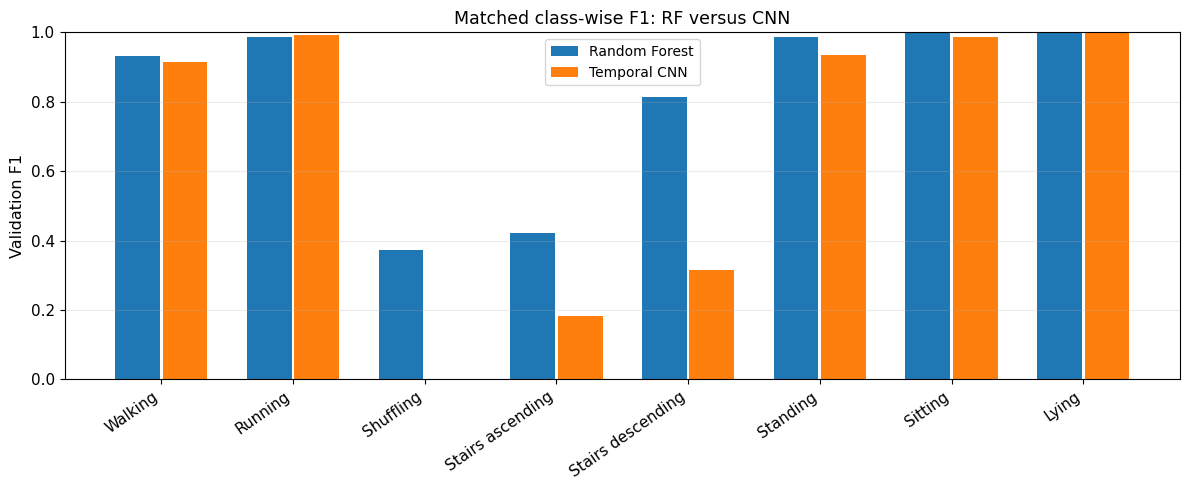

In [58]:
# ================ 07. Compare Same-Window Validation Metrics =================

# ----------------------- 1. Compare Validation Metrics -----------------------
predictions = {
    "Random Forest": rf_prediction,
    "Temporal CNN": cnn_prediction,
}
comparison = pd.DataFrame([
    {"model": name,
     "macro_f1": f1_score(y_val, prediction, labels=TASK_CLASSES,
                         average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, prediction),
     "validation_windows": len(y_val)}
    for name, prediction in predictions.items()
])

display(comparison.round(4))

# -------------------------- 2. Inspect Per-Class F1 --------------------------
reports = []

for name, prediction in predictions.items():
    item = classification_class_report(
        y_val, prediction, classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[k] for k in TASK_CLASSES],
    )
    item["model"] = name
    reports.append(item)

class_table = pd.concat(reports, ignore_index=True)

display(class_table[["model", "class", "support", "precision", "recall", "f1"]].round(3))
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(8)

for i, name in enumerate(predictions):
    values = class_table.loc[class_table["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 0.5) * 0.36, values, width=0.34, label=name)

ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")
ax.set(ylabel="Validation F1", title="Matched class-wise F1: RF versus CNN",
       ylim=(0, 1))
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "11_matched_per_class_f1.png")
plt.show()


**08. Inspect Matched Validation Confusion Matrices**

Compare classification errors across the eight activities, including Shuffling and stair activities. These are Development Validation diagnostics, not final Test results.

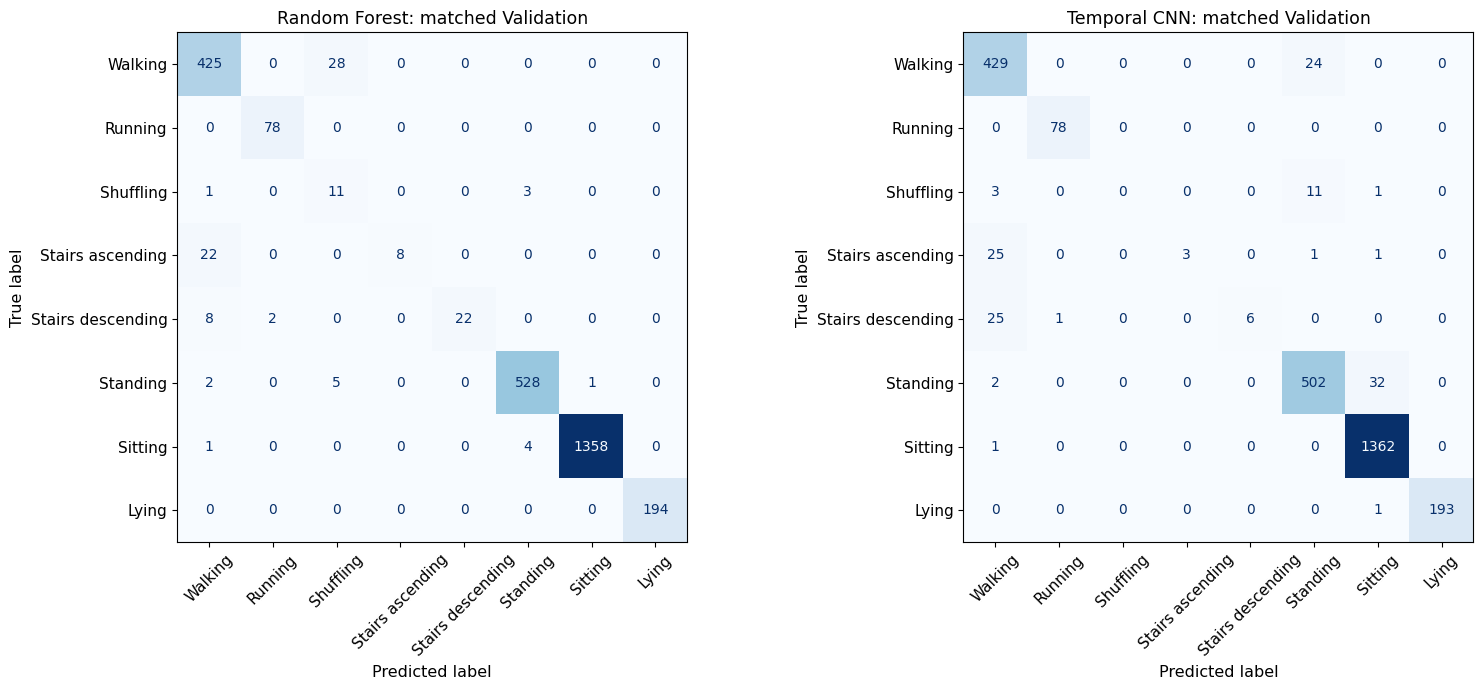

In [59]:
# ================== 08. Inspect Matched Confusion Matrices ===================
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, prediction) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_val, prediction, labels=TASK_CLASSES)
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    ).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}: matched Validation")

fig.tight_layout()
save_figure(fig, output_dir / "11_matched_confusion_matrices.png")
plt.show()


**09. Compare Paired Held-Out Participant Scores**

Compare fixed-task Macro F1 for each of the six Validation participants. Participant-level differences are descriptive; overlapping windows are not treated as independent people.

,model,subject_id,windows,observed_classes,accuracy,macro_f1_fixed_task,macro_f1_observed_classes
0,Random Forest,S009,201,4,0.8905,0.3556,0.7112
6,Temporal CNN,S009,201,4,0.8905,0.2318,0.4636
1,Random Forest,S012,500,8,0.9880,0.8605,0.8605
7,Temporal CNN,S012,500,8,0.9800,0.5911,0.5911
2,Random Forest,S019,500,8,0.9880,0.8680,0.8680
8,Temporal CNN,S019,500,8,0.9580,0.5882,0.5882
3,Random Forest,S022,500,8,0.9660,0.7516,0.7516
9,Temporal CNN,S022,500,8,0.9600,0.6290,0.6290
4,Random Forest,S036,500,6,0.9820,0.6180,0.8240
10,Temporal CNN,S036,500,6,0.9200,0.5745,0.7660


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.2318,0.3556,-0.1238
1,S012,0.5911,0.8605,-0.2694
2,S019,0.5882,0.8680,-0.2798
3,S022,0.6290,0.7516,-0.1226
4,S036,0.5745,0.6180,-0.0434
5,S037,0.7463,0.8132,-0.0670


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Temporal CNN,Random Forest,macro_f1_fixed_task,6,-0.151,-0.1232,0,6,0


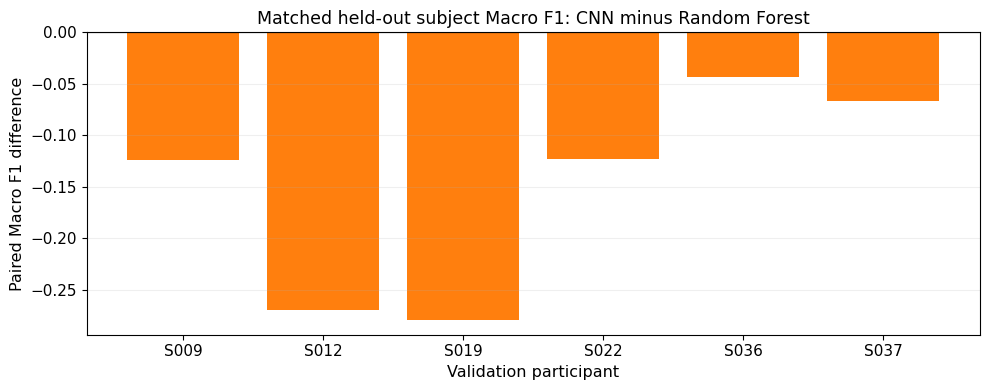

In [60]:
# ================ 09. Pair Held-Out Participant Model Scores =================

# -------------------- 1. Compare Participant-Level Scores --------------------
subject_results = pd.concat([
    evaluate_predictions_by_subject(
        y_true=y_val, y_pred=prediction, subject_ids=val_subject_ids,
        classes=TASK_CLASSES, model_name=name,
    )
    for name, prediction in predictions.items()
], ignore_index=True)

display(subject_results.sort_values(["subject_id", "model"]).round(4))
paired, paired_summary = compare_models_by_subject(
    subject_results, model_a="Temporal CNN",
    model_b="Random Forest", score_column="macro_f1_fixed_task",  # Compare models on the same fixed eight classes.
)

# ------------------- 2. Visualise Paired Model Differences -------------------
display(paired.round(4))
display(pd.DataFrame([paired_summary]).round(4))
fig, ax = plt.subplots(figsize=(10, 4))

difference = paired["difference_a_minus_b"]

ax.bar(paired["subject_id"], difference,
       color=["tab:blue" if d >= 0 else "tab:orange" for d in difference])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Matched held-out subject Macro F1: CNN minus Random Forest",
       xlabel="Validation participant", ylabel="Paired Macro F1 difference")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "11_matched_participant_difference.png")
plt.show()


**10. Matched-Data Quality Gate and Limitations**

Verify identical source rows, labels and subject groups across the two models. The models use different input representations, and the 500-window cap restricts this experiment. The comparison cannot isolate an architectural effect or establish independent generalisation.

In [61]:
# =============== 10. Matched-Protocol Scientific Quality Gate ================

# ---------------- 1. Verify Source and Participant Alignment -----------------
assert len(y_val) == len(rf_prediction) == len(cnn_prediction)
assert not (set(val_subject_ids) & RESERVED_TEST)
assert set(subject_results["subject_id"]) == set(val_subject_ids)
assert set(paired["subject_id"]) == set(val_subject_ids)
assert len(group_members["validation"]) == len(paired)

# ----------------- 2. Check Prediction and Metric Integrity ------------------
assert comparison["macro_f1"].between(0, 1).all()
assert np.isfinite(X_rf_val.to_numpy()).all()

# ---------------------- 3. Quality Gate and Boundaries -----------------------
print("Matched source windows / split / labels: PASSED")
print("Original Test loaded or evaluated: NO")
print("Model family difference conclusively established: NO")

# ---------------------- 4. Export Matched Validation Evidence ----------------
overview.to_csv(output_dir / "11_development_cohort_summary.csv", index=False)
split_summary = pd.DataFrame([
    {"partition": name, "subject_id": subject}
    for name, people in group_members.items()
    for subject in sorted(people)
])
split_summary.to_csv(output_dir / "11_development_partition_membership.csv", index=False)
history.to_csv(output_dir / "11_cnn_training_history.csv", index=False)
comparison.to_csv(output_dir / "11_matched_model_validation_metrics.csv", index=False)
class_table.to_csv(output_dir / "11_matched_validation_class_metrics.csv", index=False)
subject_results.to_csv(output_dir / "11_matched_validation_subject_metrics.csv", index=False)
paired.to_csv(output_dir / "11_matched_validation_paired_subjects.csv", index=False)
pd.DataFrame([paired_summary]).to_csv(
    output_dir / "11_matched_validation_paired_summary.csv", index=False
)
pd.DataFrame({
    "subject_id": val_subject_ids,
    "true_source_code": y_val,
    "rf_predicted_source_code": rf_prediction,
    "cnn_predicted_source_code": cnn_prediction,
}).to_csv(output_dir / "11_matched_validation_predictions.csv", index=False)
for name, prediction in predictions.items():
    safe_name = "random_forest" if name == "Random Forest" else "temporal_cnn"
    matrix = confusion_matrix(y_val, prediction, labels=TASK_CLASSES)
    pd.DataFrame(matrix, index=TASK_CLASSES, columns=TASK_CLASSES).rename_axis(
        "true_source_code"
    ).to_csv(output_dir / f"11_{safe_name}_validation_confusion.csv")

# Trained model artefacts remain local by default under the existing .gitignore.
from joblib import dump as dump_joblib
dump_joblib(rf, output_dir / "11_matched_random_forest.joblib")
torch.save({
    "model_state_dict": {k: v.detach().cpu() for k, v in cnn.state_dict().items()},
    "architecture": {"name": "TemporalCNN", "in_channels": 6,
                     "n_classes": 8, "hidden_channels": 32},
    "train_only_channel_mean": scaler["channel_mean"].tolist(),
    "train_only_channel_std": scaler["channel_std"].tolist(),
    "task_classes": list(TASK_CLASSES),
}, output_dir / "11_matched_temporal_cnn.pt")
print("Saved matched Development Validation results in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="11")

Matched source windows / split / labels: PASSED
Original Test loaded or evaluated: NO
Model family difference conclusively established: NO
Saved matched Development Validation results in: /content/human-movement-intelligence/wearable_activity_recognition/output
